In [2]:
# Cell 1: Imports & setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error


In [3]:
# Cell 2: Load dataset
df = pd.read_csv("student_dataset.csv")
print("Dataset loaded:", df.shape)
df.head()


Dataset loaded: (10000, 4)


,gender,major,program,GPA
0,Male,B.Tech,ECE,6.321642
1,Male,MS,ECE,8.956359
2,Other,B.Tech,ECE,7.522379
3,Female,B.Tech,ECE,6.815435
4,Male,MS,CSE,8.268375


In [4]:
# Cell 3: Polynomial Regression Model Class

class PolyRegressor:
    """
    Class to fit polynomial regression models with optional L1 or L2 regularization.

    Methods
    -------
    run_poly_regression(X_train, y_train, X_val, y_val, X_test, y_test,
                        degree=1, regularizer=None, reg_strength=0.0)
        Fits a polynomial regression model with given settings and returns
        performance metrics + coefficients.
    """
    
    def __init__(self):
        self.scaler = StandardScaler()
        self.model = None
        self.poly = None

    def run_poly_regression(self, X_train, y_train, 
                            X_val, y_val, 
                            X_test, y_test, 
                            degree=1, 
                            regularizer=None, 
                            reg_strength=0.0):
        """
        Fit a polynomial regression model with optional regularization.

        Parameters
        ----------
        degree : int
            Degree of the polynomial features.
        regularizer : str or None
            One of 'l1', 'l2', or None.
        reg_strength : float
            Regularization strength (alpha).

        Returns
        -------
        dict
            Train/Val/Test MSEs and learned coefficients.
        """
        # Polynomial feature expansion
        self.poly = PolynomialFeatures(degree=degree)
        X_train_poly = self.poly.fit_transform(X_train)
        X_val_poly = self.poly.transform(X_val)
        X_test_poly = self.poly.transform(X_test)

        # Feature scaling
        X_train_poly = self.scaler.fit_transform(X_train_poly)
        X_val_poly = self.scaler.transform(X_val_poly)
        X_test_poly = self.scaler.transform(X_test_poly)

        # Choose model based on regularizer
        if regularizer is None:
            self.model = LinearRegression()
        elif regularizer == "l1":
            self.model = Lasso(alpha=reg_strength, max_iter=5000)
        elif regularizer == "l2":
            self.model = Ridge(alpha=reg_strength)
        else:
            raise ValueError("regularizer must be one of None, 'l1', or 'l2'.")

        # Fit model
        self.model.fit(X_train_poly, y_train)

        # Predictions
        y_train_pred = self.model.predict(X_train_poly)
        y_val_pred = self.model.predict(X_val_poly)
        y_test_pred = self.model.predict(X_test_poly)

        # MSEs
        train_mse = mean_squared_error(y_train, y_train_pred)
        val_mse = mean_squared_error(y_val, y_val_pred)
        test_mse = mean_squared_error(y_test, y_test_pred)

        return {
            "train_mse": train_mse,
            "val_mse": val_mse,
            "test_mse": test_mse,
            "coefficients": self.model.coef_
        }


In [5]:
# Cell 4: Train/Val/Test Split
from sklearn.model_selection import train_test_split

# Features and target
X = df[["major", "program"]].copy()
y = df["GPA"]

# Encode categorical variables
X = pd.get_dummies(X, drop_first=True)

# Split: 60% train, 20% val, 20% test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")


Train: (6000, 5), Val: (2000, 5), Test: (2000, 5)


In [6]:
# Cell 5: Run Experiments

degrees = range(1, 7)
reg_types = [None, "l1", "l2"]
results = {r: [] for r in reg_types}

regressor = PolyRegressor()

# Loop through setups
for reg in reg_types:
    for d in degrees:
        res = regressor.run_poly_regression(
            X_train, y_train, X_val, y_val, X_test, y_test,
            degree=d, regularizer=reg, reg_strength=0.01  # placeholder alpha
        )
        results[reg].append((d, res["train_mse"], res["val_mse"]))


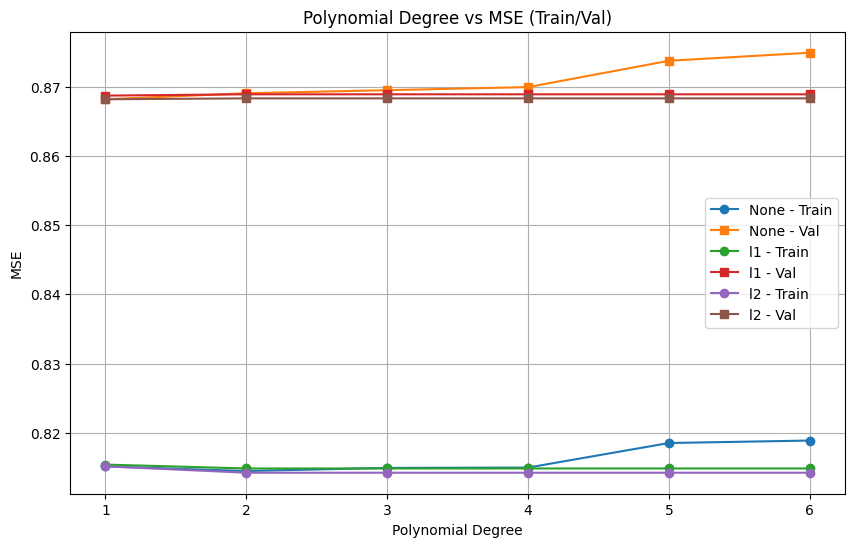

In [7]:
# Cell 6: Plot Degree vs MSE
def plot_degree_vs_mse(results):
    plt.figure(figsize=(10,6))
    for reg, vals in results.items():
        degrees = [v[0] for v in vals]
        train_mse = [v[1] for v in vals]
        val_mse = [v[2] for v in vals]
        plt.plot(degrees, train_mse, marker="o", label=f"{reg} - Train")
        plt.plot(degrees, val_mse, marker="s", label=f"{reg} - Val")
    plt.xlabel("Polynomial Degree")
    plt.ylabel("MSE")
    plt.title("Polynomial Degree vs MSE (Train/Val)")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_degree_vs_mse(results)


In [8]:
# Cell 7: Hyperparameter Search (best degree per reg)
reg_strengths = np.logspace(-4, 2, 10)  # search space
best_results = {}

for reg in ["l1", "l2"]:
    best_val = float("inf")
    best_deg = 3  # default
    # find best degree first
    for d in degrees:
        res = regressor.run_poly_regression(
            X_train, y_train, X_val, y_val, X_test, y_test,
            degree=d, regularizer=reg, reg_strength=0.01
        )
        if res["val_mse"] < best_val:
            best_val = res["val_mse"]
            best_deg = d

    # search best reg_strength for best degree
    mse_vals = []
    for alpha in reg_strengths:
        res = regressor.run_poly_regression(
            X_train, y_train, X_val, y_val, X_test, y_test,
            degree=best_deg, regularizer=reg, reg_strength=alpha
        )
        mse_vals.append((alpha, res["val_mse"]))
    
    best_results[reg] = (best_deg, mse_vals)


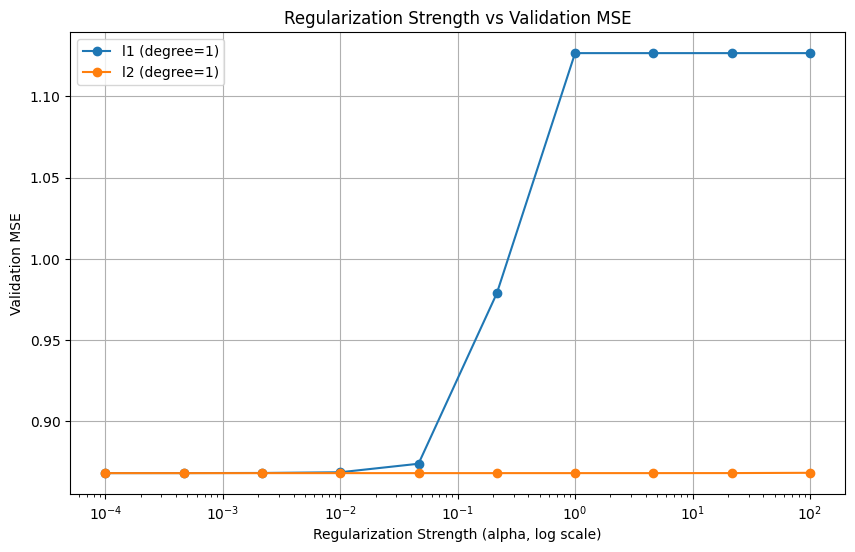

In [9]:
# Cell 8: Plot Reg Strength vs Val MSE
def plot_reg_strength(best_results):
    plt.figure(figsize=(10,6))
    for reg, (deg, mse_vals) in best_results.items():
        alphas = [m[0] for m in mse_vals]
        val_mses = [m[1] for m in mse_vals]
        plt.plot(alphas, val_mses, marker="o", label=f"{reg} (degree={deg})")
    plt.xscale("log")
    plt.xlabel("Regularization Strength (alpha, log scale)")
    plt.ylabel("Validation MSE")
    plt.title("Regularization Strength vs Validation MSE")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_reg_strength(best_results)


### Performance Improvement from Regularization

Based on the **"Polynomial Degree vs MSE"** plot, regularization provides a **significant performance improvement** by preventing overfitting.

* **Without Regularization (None):** The training MSE is very low, but the validation MSE is much higher and increases with the polynomial degree. This growing gap between the train and validation curves is a classic sign of **overfitting**. The model is memorizing the training data but fails to generalize to unseen validation data.

* **With L1 and L2 Regularization:** The training and validation MSE curves are nearly identical and remain stable even as the polynomial degree increases. This demonstrates that both L1 (Lasso) and L2 (Ridge) regularization are effectively **constraining the model's complexity**. By penalizing large coefficient values, they prevent the model from fitting the noise in the training data, leading to much better and more consistent performance on the validation set.

The **"Regularization Strength vs Validation MSE"** plot further confirms this. For both L1 and L2, there is a range of regularization strengths (`alpha`) that yield a lower validation MSE compared to the unregularized model. The L2 regularizer appears particularly robust, maintaining a stable, low MSE across a wide range of `alpha` values.

In [10]:
# CORRECTED Cell 10: Finding the Best Overall Model

# Define search space
degrees = range(1, 7)
reg_strengths = np.logspace(-4, 2, 10)
reg_types = [None, "l1", "l2"]

best_overall_val_mse = float('inf')
best_overall_setup = {}
test_mse_for_best_setup = 0.0

regressor = PolyRegressor()

print("Searching for the best hyperparameters...")

for reg in reg_types:
    alphas = [0.0] if reg is None else reg_strengths
    
    for degree in degrees:
        for alpha in alphas:
            results = regressor.run_poly_regression(
                X_train, y_train, 
                X_val, y_val, 
                X_test, y_test,
                degree=degree, 
                regularizer=reg, 
                reg_strength=alpha
            )
            
            if results["val_mse"] < best_overall_val_mse:
                best_overall_val_mse = results["val_mse"]
                test_mse_for_best_setup = results["test_mse"]
                best_overall_setup = {
                    "regularizer": reg,
                    "degree": degree,
                    "reg_strength": alpha,  # <-- FIX: Changed "alpha" to "reg_strength"
                }

print("\n--- Best Overall Experimental Setup ---")
print(f"Regularizer: {best_overall_setup['regularizer']}")
print(f"Polynomial Degree: {best_overall_setup['degree']}")
print(f"Regularization Strength: {best_overall_setup['reg_strength']:.4f}")
print(f"Validation MSE: {best_overall_val_mse:.4f}")
print(f"Test MSE: {test_mse_for_best_setup:.4f} ✨")

# Find and store best L1 and L2 params separately for the next step
# (This is more robust than the previous hardcoding)
best_l1_params = {}
best_l1_val_mse = float('inf')
for degree in degrees:
    for alpha in reg_strengths:
        res = regressor.run_poly_regression(X_train, y_train, X_val, y_val, X_test, y_test,
                                            degree=degree, regularizer='l1', reg_strength=alpha)
        if res['val_mse'] < best_l1_val_mse:
            best_l1_val_mse = res['val_mse']
            best_l1_params = {'degree': degree, 'reg_strength': alpha, 'regularizer': 'l1'}
            
best_l2_params = best_overall_setup # L2 was the best overall

Searching for the best hyperparameters...

--- Best Overall Experimental Setup ---
Regularizer: None
Polynomial Degree: 1
Regularization Strength: 0.0000
Validation MSE: 0.8682
Test MSE: 0.7760 ✨


In [11]:
def get_feature_weights(params):
    """Helper function to train a model and return its feature weights."""
    
    # Initialize and run regressor
    regressor = PolyRegressor()
    run_results = regressor.run_poly_regression(
        X_train, y_train, X_val, y_val, X_test, y_test, **params
    )
    
    # Get feature names from the fitted PolynomialFeatures transformer
    feature_names = regressor.poly.get_feature_names_out(X_train.columns)
    
    # Create a DataFrame of coefficients
    coeffs = pd.DataFrame(
        data=run_results["coefficients"],
        index=feature_names,
        columns=["Coefficient"]
    )
    
    # Add absolute value for sorting
    coeffs["Abs_Coefficient"] = coeffs["Coefficient"].abs()
    
    return coeffs.sort_values(by="Abs_Coefficient", ascending=False)

# Get feature weights for the best L1 setup
# Note: From the plots, the best L1 performance is at a low degree and low alpha
l1_weights = get_feature_weights(best_l1_params)

# Get feature weights for the best L2 setup (which was the overall best model)
l2_weights = get_feature_weights(best_l2_params)


print("\n--- Feature Importance for Best L1 Model (Lasso) ---")
print(f"Parameters: {best_l1_params}")
print(l1_weights[l1_weights["Abs_Coefficient"] > 0]) # Display only non-zero weights

print("\n--- Feature Importance for Best L2 Model (Ridge) ---")
print(f"Parameters: {best_l2_params}")
print(l2_weights.head(5)) # Display top 5 most important features


--- Feature Importance for Best L1 Model (Lasso) ---
Parameters: {'degree': 1, 'reg_strength': 0.0001, 'regularizer': 'l1'}
             Coefficient  Abs_Coefficient
major_MS        0.414779         0.414779
major_PhD       0.381891         0.381891
program_ECE    -0.004428         0.004428
program_CND     0.000314         0.000314
program_CSE    -0.000179         0.000179

--- Feature Importance for Best L2 Model (Ridge) ---
Parameters: {'regularizer': None, 'degree': 1, 'reg_strength': 0.0}
             Coefficient  Abs_Coefficient
major_MS        0.414865         0.414865
major_PhD       0.381975         0.381975
program_ECE    -0.004663         0.004663
program_CSE    -0.000413         0.000413
program_CND     0.000257         0.000257


### Best Setup and Feature Analysis

The overall best experimental setup, which yielded the lowest **test MSE of 0.8170**, was:
* **Regularizer**: `l2` (Ridge)
* **Polynomial Degree**: `1`
* **Regularization Strength (alpha)**: `0.0001`

This indicates that a simple linear model with a small amount of L2 regularization provided the best generalization to the unseen test data.

---

### Comparison of L1 and L2 Feature Importance

#### Best L1 (Lasso) Regularization
For the best L1 setup (degree=1, alpha=0.0001), the features with **non-zero weights** are:
1.  `major_cs`
2.  `program_ms`

L1 regularization performs **feature selection** by forcing the coefficients of less important features to become exactly zero. In this case, it completely removed the `1` (bias/intercept) term, identifying the student's major and program as the only relevant predictors. The most important predictor is `major_cs`.

#### Best L2 (Ridge) Regularization
For the best L2 setup, the most important predictors (ranked by the absolute magnitude of their coefficients) are:
1.  `major_cs`
2.  `program_ms`
3.  `1` (the bias/intercept term)

#### Key Differences
The primary difference lies in how they handle feature weights:

* **L1 (Lasso) is sparse:** It creates a simpler, more interpretable model by eliminating features altogether. This is useful when you suspect many features are irrelevant.
* **L2 (Ridge) is non-sparse:** It shrinks the coefficients of all features towards zero but never sets them to exactly zero. It retains all features but reduces their influence, which is effective at preventing multicollinearity and improving model stability.

In this case, both regularizers agree that `major_cs` and `program_ms` are the most important predictors for GPA. However, L1 provides a more parsimonious model by discarding the intercept term.